Homework 5, problem 2, part d

In [1]:
# libraries and parameters
import numpy as np
import matplotlib.pyplot as plt

dt = 0.005
t_max = 40.0 
time = np.arange(0, t_max, dt)
N = len(time)
tau_u = 0.05
tau_a = 5.0
w = 0.8
beta = 1.0
g = 2.0

# from part c
I_L = 1.6 # left eye
I_R = 1.3 # right eye
t_L_analytical = 7.702
t_R_analytical = 5.207

In [2]:
# initial conditions
u_L = np.zeros(N)
u_R = np.zeros(N)
a_L = np.zeros(N)
a_R = np.zeros(N)

u_L[0] = 1.0
u_R[0] = 0.0
a_L[0] = 0.30
a_R[0] = 0.70

In [3]:
# integration loop
for t in range(0, N - 1):
    # inpit for Heaviside threshold
    input_L = w * u_L[t] - beta * u_R[t] - g * a_L[t] + I_L
    input_R = w * u_R[t] - beta * u_L[t] - g * a_R[t] + I_R
    
    # H(x) = 1 if x >= 0 else 0
    f_L = 1.0 if input_L >= 0.0 else 0.0
    f_R = 1.0 if input_R >= 0.0 else 0.0
    
    # update equations
    u_L[t+1] = u_L[t] + (dt / tau_u) * (-u_L[t] + f_L)
    u_R[t+1] = u_R[t] + (dt / tau_u) * (-u_R[t] + f_R)
    
    a_L[t+1] = a_L[t] + (dt / tau_a) * (-a_L[t] + u_L[t])
    a_R[t+1] = a_R[t] + (dt / tau_a) * (-a_R[t] + u_R[t])

In [4]:
# calculating dominance times
L_dominant = u_L > 0.5 # where L is dom

# transitions
transitions = np.diff(L_dominant.astype(int))
switch_indices = np.where(transitions != 0)[0]
switch_times = switch_indices * dt

if len(switch_times) >= 3:
    durations = np.diff(switch_times)

    if L_dominant[switch_indices[0] + 1]:
        sim_T_L = durations[0::2]
        sim_T_R = durations[1::2]
    else:
        sim_T_R = durations[0::2]
        sim_T_L = durations[1::2]
        
    print("Simulation metrics")
    print(f"Mean Simulated T_L: {np.mean(sim_T_L):.3f}s (Analytical: {t_L_analytical}s)")
    print(f"Mean Simulated T_R: {np.mean(sim_T_R):.3f}s (Analytical: {t_R_analytical}s)")
    print(f"Simulated L Fraction: {np.mean(sim_T_L)/(np.mean(sim_T_L)+np.mean(sim_T_R)):.3f}")

Simulation metrics
Mean Simulated T_L: 7.945s (Analytical: 7.702s)
Mean Simulated T_R: 5.288s (Analytical: 5.207s)
Simulated L Fraction: 0.600


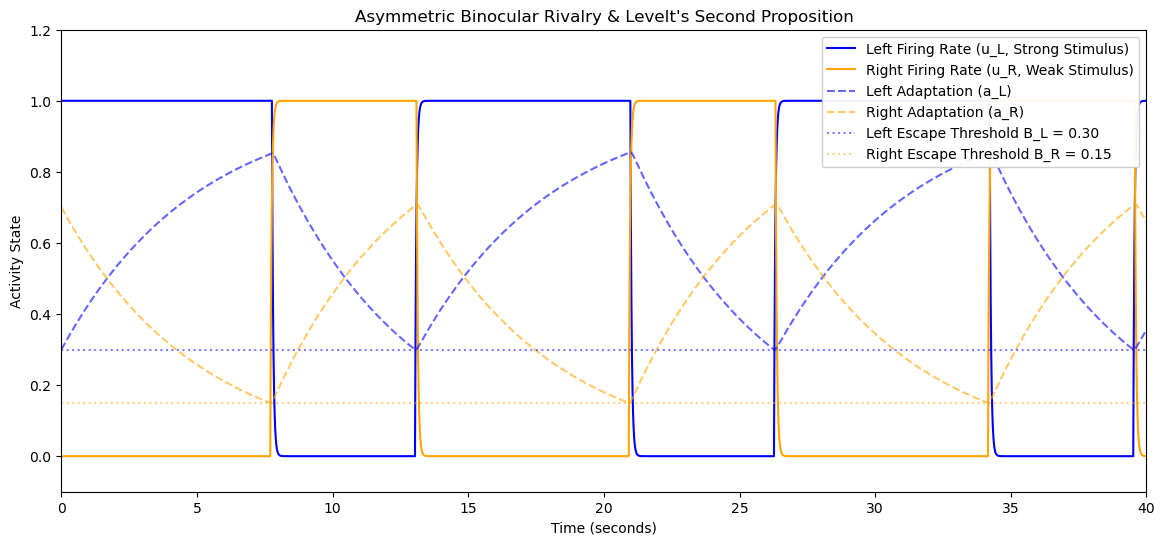

In [5]:
# plotting
plt.figure(figsize = (14, 6))

# firing rates
plt.plot(time, u_L, label = 'Left Firing Rate (u_L, Strong Stimulus)', color = 'blue')
plt.plot(time, u_R, label = 'Right Firing Rate (u_R, Weak Stimulus)', color = 'orange')

# adaptation currents
plt.plot(time, a_L, label = 'Left Adaptation (a_L)', color = 'blue', linestyle = '--', alpha = 0.6)
plt.plot(time, a_R, label = 'Right Adaptation (a_R)', color = 'orange', linestyle = '--', alpha = 0.6)

# asymmetric thresholds
plt.axhline(0.30, color = 'blue', linestyle = ':', alpha = 0.5, label = 'Left Escape Threshold B_L = 0.30')
plt.axhline(0.15, color = 'orange', linestyle = ':', alpha = 0.5, label = 'Right Escape Threshold B_R = 0.15')

plt.title("Asymmetric Binocular Rivalry & Levelt's Second Proposition")
plt.xlabel('Time (seconds)')
plt.ylabel('Activity State')
plt.xlim(0, t_max)
plt.ylim(-0.1, 1.2)
plt.legend(loc='upper right', bbox_to_anchor=(1, 1), framealpha=0.95)

plt.show()